# Kex

> Transfer of a CNN for exchangeable potassium (Kex) from OSSL to Fukushima: zero-shot, head-only, fine-tuned, fully fine-tuned and Fukushima-only models, with schedules chosen by cross-validation

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspecdl.all import plot_cv
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). `02_transfer` defines the functions used here.

## Data

OSSL MIR spectra on the shared grid, with Kex in cmolc/kg. The models predict `log1p(Kex)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57674, 1675)

The Fukushima spectra, with Kex converted from mg K₂O per 100 g to cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
yt = yf[is_test]
Xf.shape, int(is_test.sum())

((1388, 1675), 341)

## Pretraining

The preprocessing is SNV followed by a Savitzky-Golay first derivative, fitted on OSSL and applied to Fukushima. `pretrain` trains on OSSL, or loads the weights of an earlier run. The table shows the last epoch of pretraining, with the R² of the OSSL validation set:

In [ ]:
#| fukudata
pipe = preprocessings()['snv_d1']
Xo_d, Xf_d = pipe.fit_transform(Xo), pipe.transform(Xf)
pretrained = pretrain(Xo_d, yo, 'ossl_kex_snv_d1')
pretrain_history('ossl_kex_snv_d1').iloc[-1].round(3).to_dict()

{'train_loss': 0.023, 'valid_loss': 0.03, 'r2_score': 0.794}

## Schedule

The fully fine-tuned and Fukushima-only models each get their own learning rate and number of epochs, chosen on the Fukushima training samples by 5-fold cross-validation. The test set plays no part. `start` gives each model's starting weights: the pretrained model, or `None` for random weights. The learning rate finder, from each starting point:

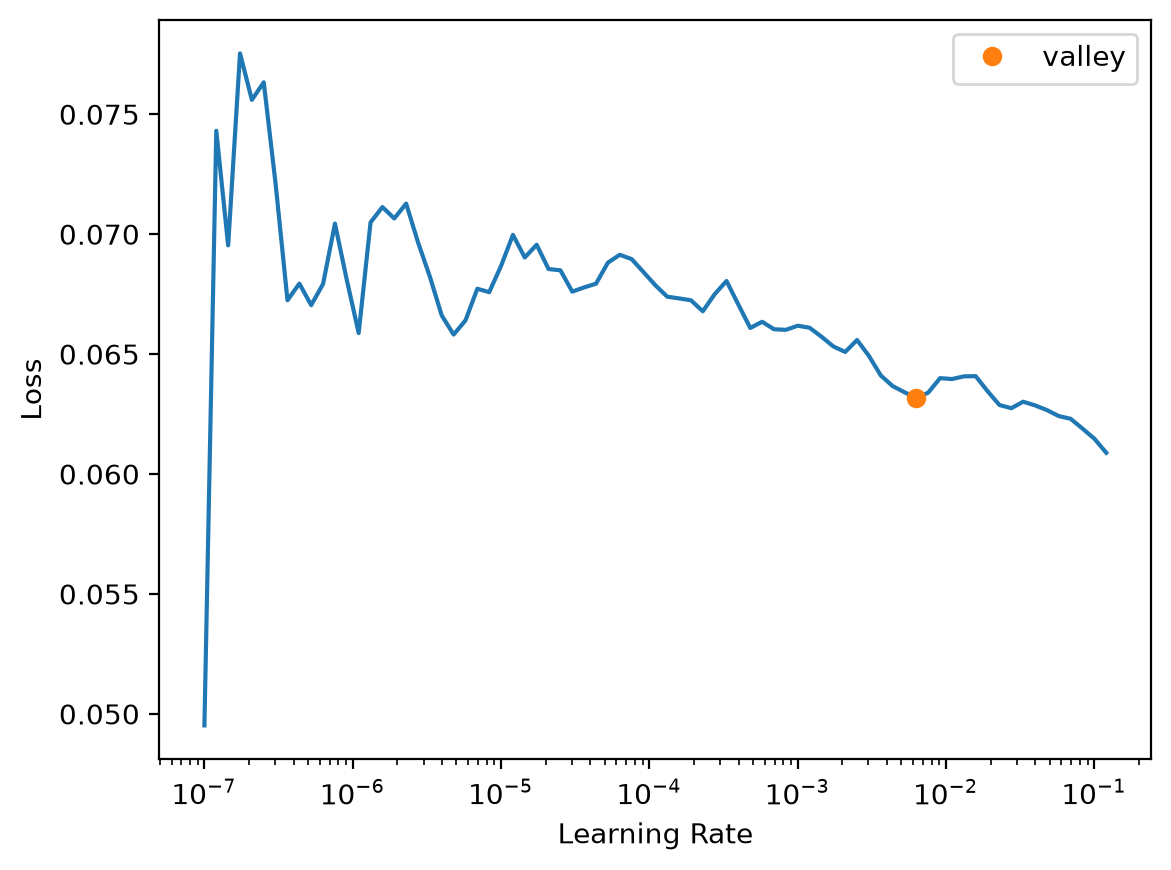

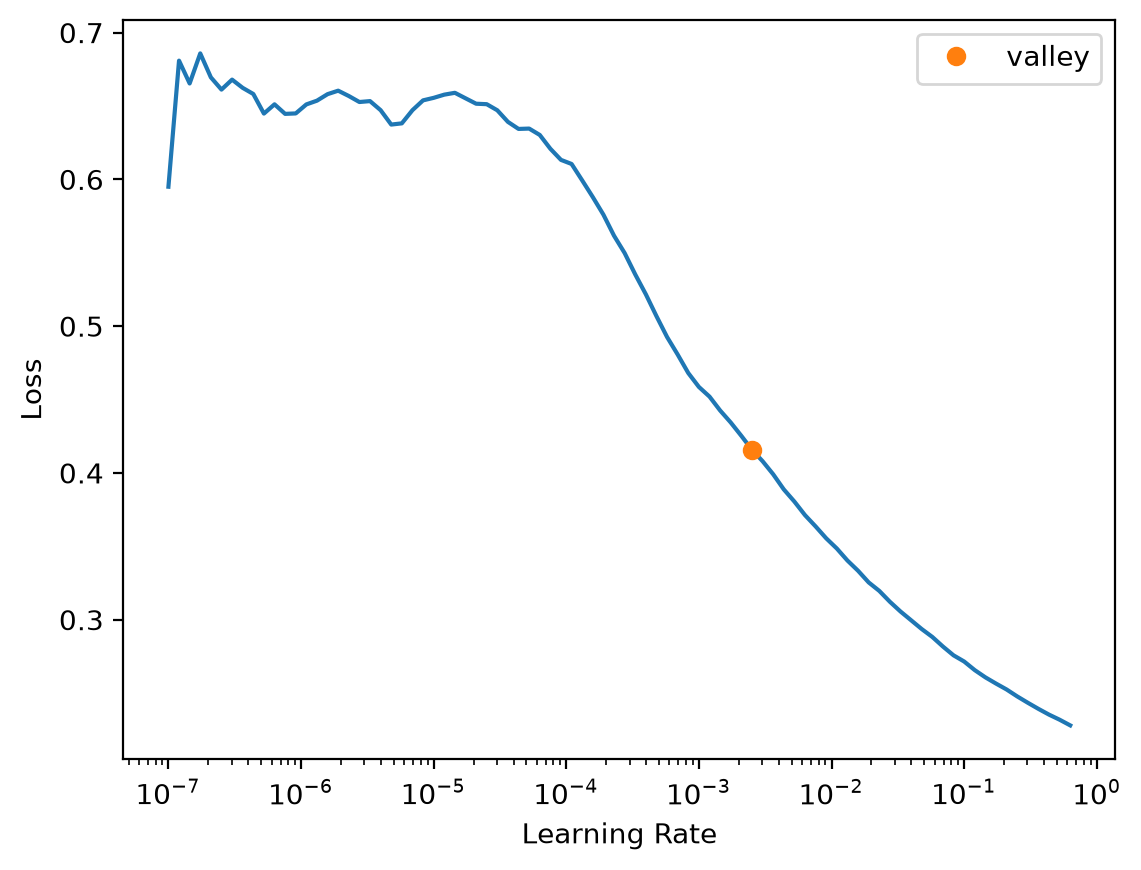

{'fully fine-tuned': 0.0063095735386013985,
 'Fukushima only': 0.002511886414140463}

In [ ]:
#| fukudata
start = {'fully fine-tuned': pretrained, 'Fukushima only': None}
mslug = {'fully fine-tuned': 'ft', 'Fukushima only': 'scratch'}
{m: float(fuku_lr_find(s, Xf_d, yf, is_test).valley) for m, s in start.items()}

Four learning rates, each with 40 one-cycle epochs. The table gives the validation loss (mean squared error of `log1p`) and R² at the last epoch, as mean and standard deviation over the folds:

In [ ]:
#| fukudata
lrs = [1e-4, 3e-4, 1e-3, 3e-3]
cv = lambda m, lr, ep: cv_curves(start[m], Xf_d, yf, is_test, lr, ep, fname=f'cv_kex_{mslug[m]}_lr{lr:g}_ep{ep}')
lr_res = {(m, lr): cv_final(cv(m, lr, 40)) for m in start for lr in lrs}
best_lr = {m: min(lrs, key=lambda lr: lr_res[m, lr]['valid_loss']) for m in start}
pd.DataFrame(lr_res).T.round(4)

valid_loss  valid_loss sd      R²   R² sd
fully fine-tuned 0.0001      0.0435         0.0058  0.2281  0.0457
                 0.0003      0.0420         0.0046  0.2537  0.0434
                 0.0010      0.0409         0.0038  0.2709  0.0619
                 0.0030      0.0405         0.0039  0.2771  0.0741
Fukushima only   0.0001      0.0448         0.0069  0.2067  0.0406
                 0.0003      0.0426         0.0047  0.2426  0.0500
                 0.0010      0.0412         0.0046  0.2678  0.0314
                 0.0030      0.0410         0.0027  0.2691  0.0536

The learning curves at each model's best learning rate, as mean over folds with a band of ±1 standard deviation:

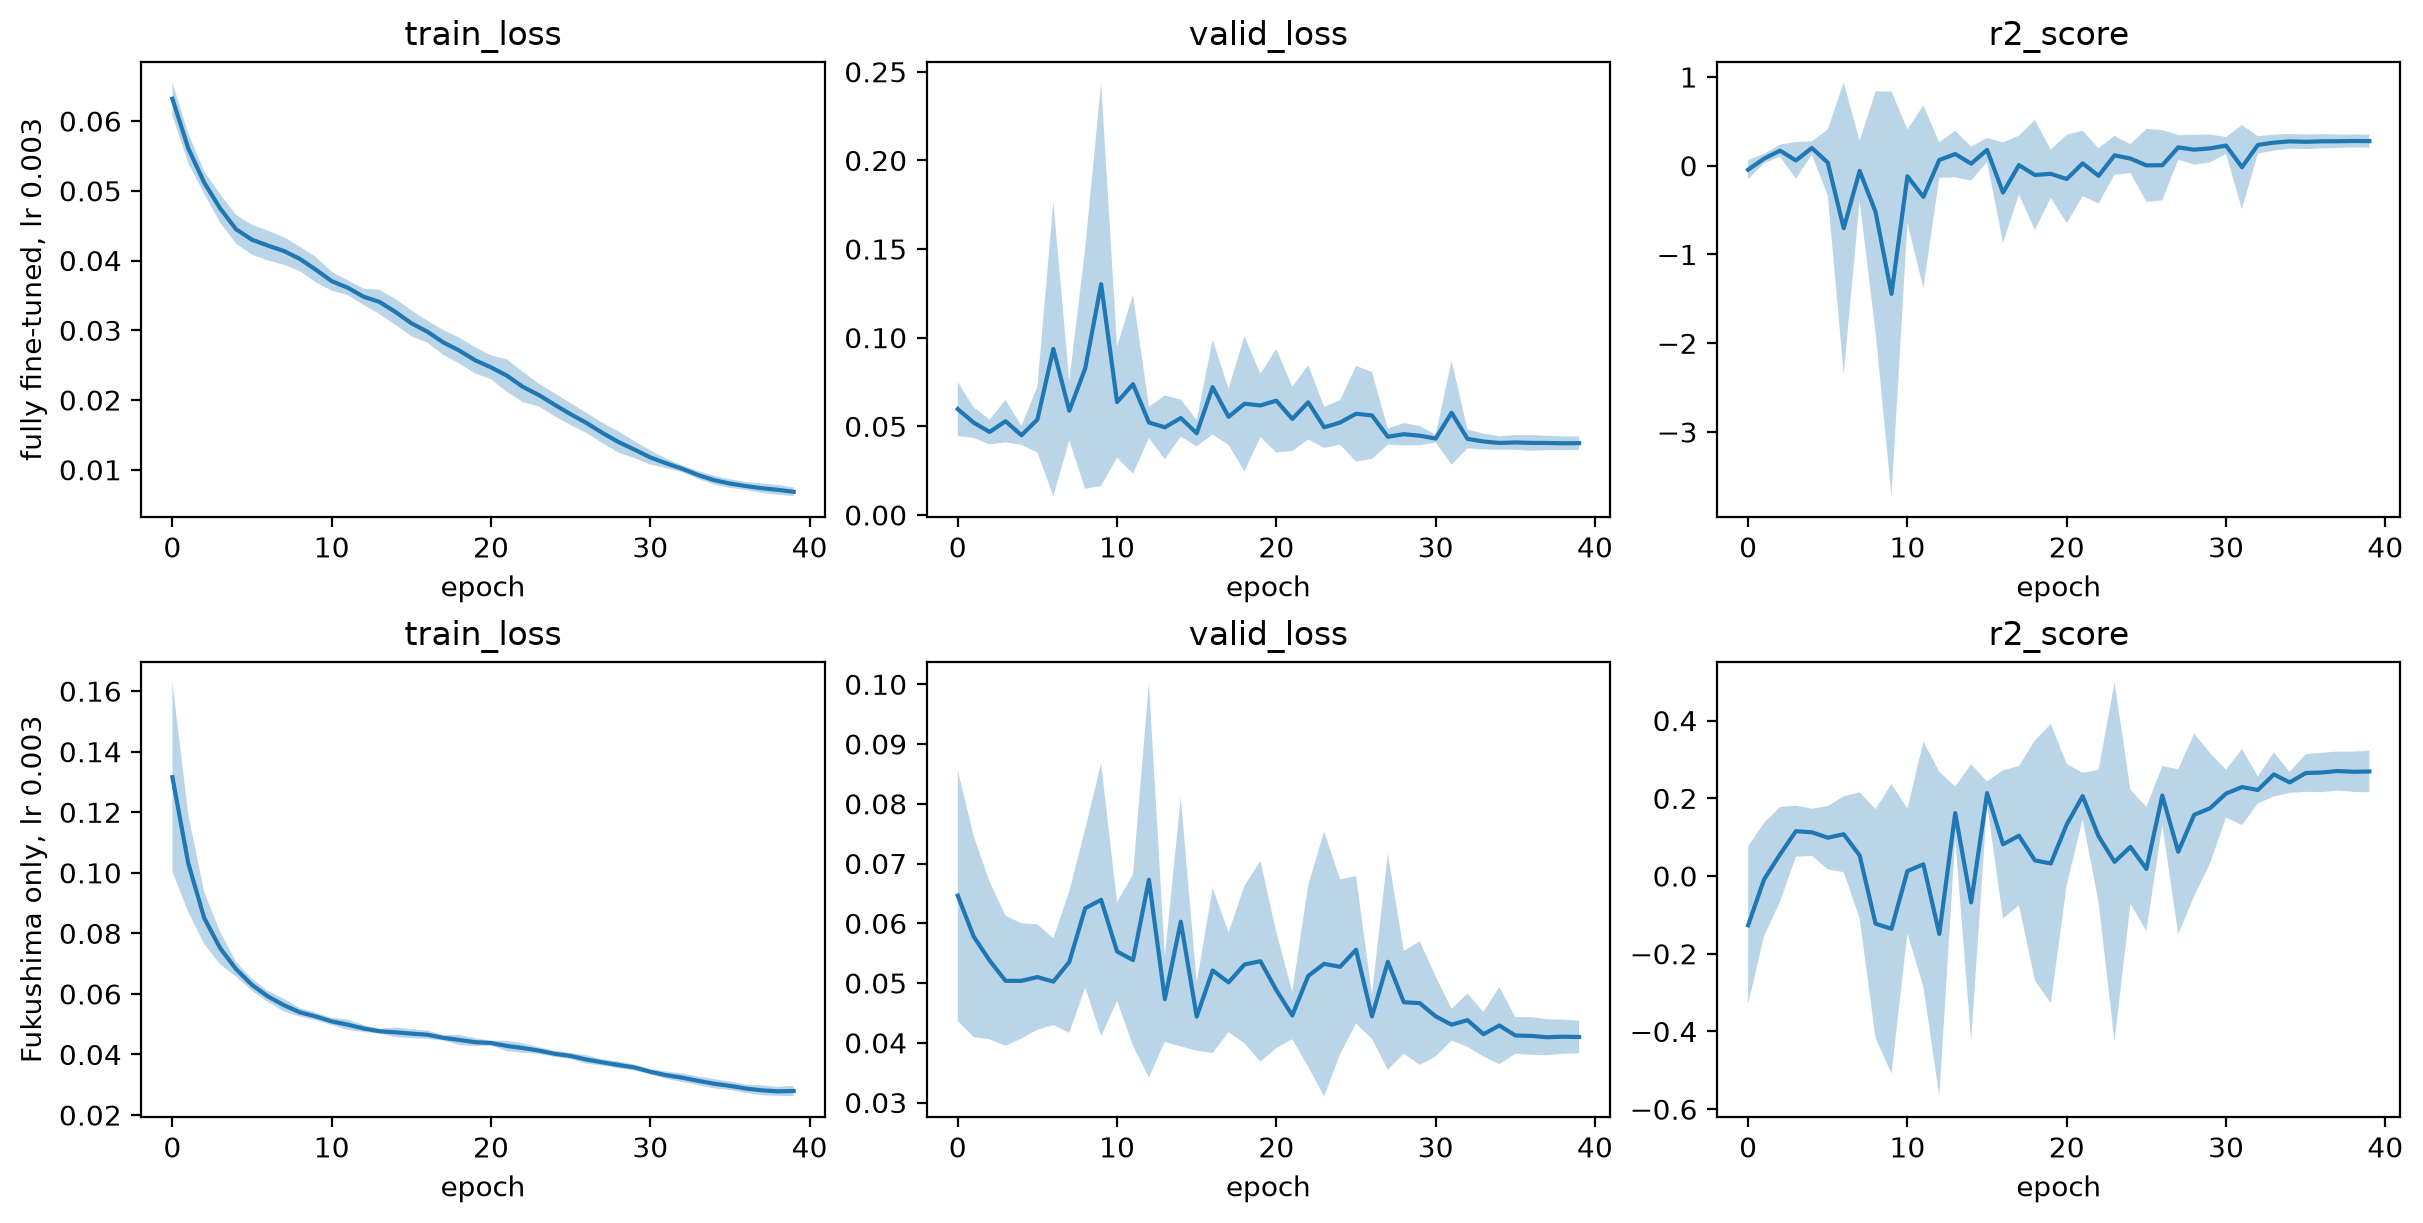

In [ ]:
#| fukudata
fig, axs = plt.subplots(2, 3, figsize=(12, 6), layout='constrained')
for row, m in zip(axs, start):
    plot_cv(cv(m, best_lr[m], 40), axs=row)
    row[0].set_ylabel(f'{m}, lr {best_lr[m]:g}')

Three numbers of epochs, at each model's best learning rate. A one-cycle schedule changes shape with its length, so each count is trained separately:

In [ ]:
#| fukudata
eps = [20, 40, 80]
ep_res = {(m, ep): cv_final(cv(m, best_lr[m], ep)) for m in start for ep in eps}
schedules = {m: (min(eps, key=lambda ep: ep_res[m, ep]['valid_loss']), best_lr[m]) for m in start}
pd.DataFrame(ep_res).T.round(4), schedules

(                     valid_loss  valid_loss sd      R²   R² sd
 fully fine-tuned 20      0.0395         0.0035  0.2954  0.0645
                  40      0.0405         0.0039  0.2771  0.0741
                  80      0.0414         0.0027  0.2598  0.0711
 Fukushima only   20      0.0417         0.0038  0.2577  0.0409
                  40      0.0410         0.0027  0.2691  0.0536
                  80      0.0443         0.0017  0.2068  0.0891,
 {'fully fine-tuned': (20, 0.003), 'Fukushima only': (40, 0.003)})

## Comparison

Each Fukushima model trains with five seeds, the fully fine-tuned and Fukushima-only models with the schedules chosen above. The other models keep their defaults. The table gives the mean and standard deviation over the seeds of R² and correlation `r` of `log1p(Kex)`, and of the RMSE and bias of Kex in cmolc/kg, on the test samples:

In [ ]:
#| fukudata
res, preds = compare({'snv_d1': pretrained}, {'snv_d1': Xf_d}, yf, is_test, schedules=schedules)
summarise(res).round(3)

R²             r  ...          bias       
                                 mean    std   mean  ...    std   mean    std
preprocessing model                                  ...                     
snv_d1        zero-shot        -0.820  0.000  0.126  ...  0.000  0.285  0.000
              head only         0.108  0.005  0.334  ...  0.002 -0.060  0.007
              fine-tuned        0.088  0.004  0.314  ...  0.001 -0.057  0.008
              fully fine-tuned  0.411  0.013  0.643  ...  0.003 -0.027  0.012
              Fukushima only    0.373  0.025  0.614  ...  0.007 -0.037  0.009

[5 rows x 8 columns]

For scale, the standard deviation of the test Kex values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

0.406

Predictions of the first seed against the observed values:

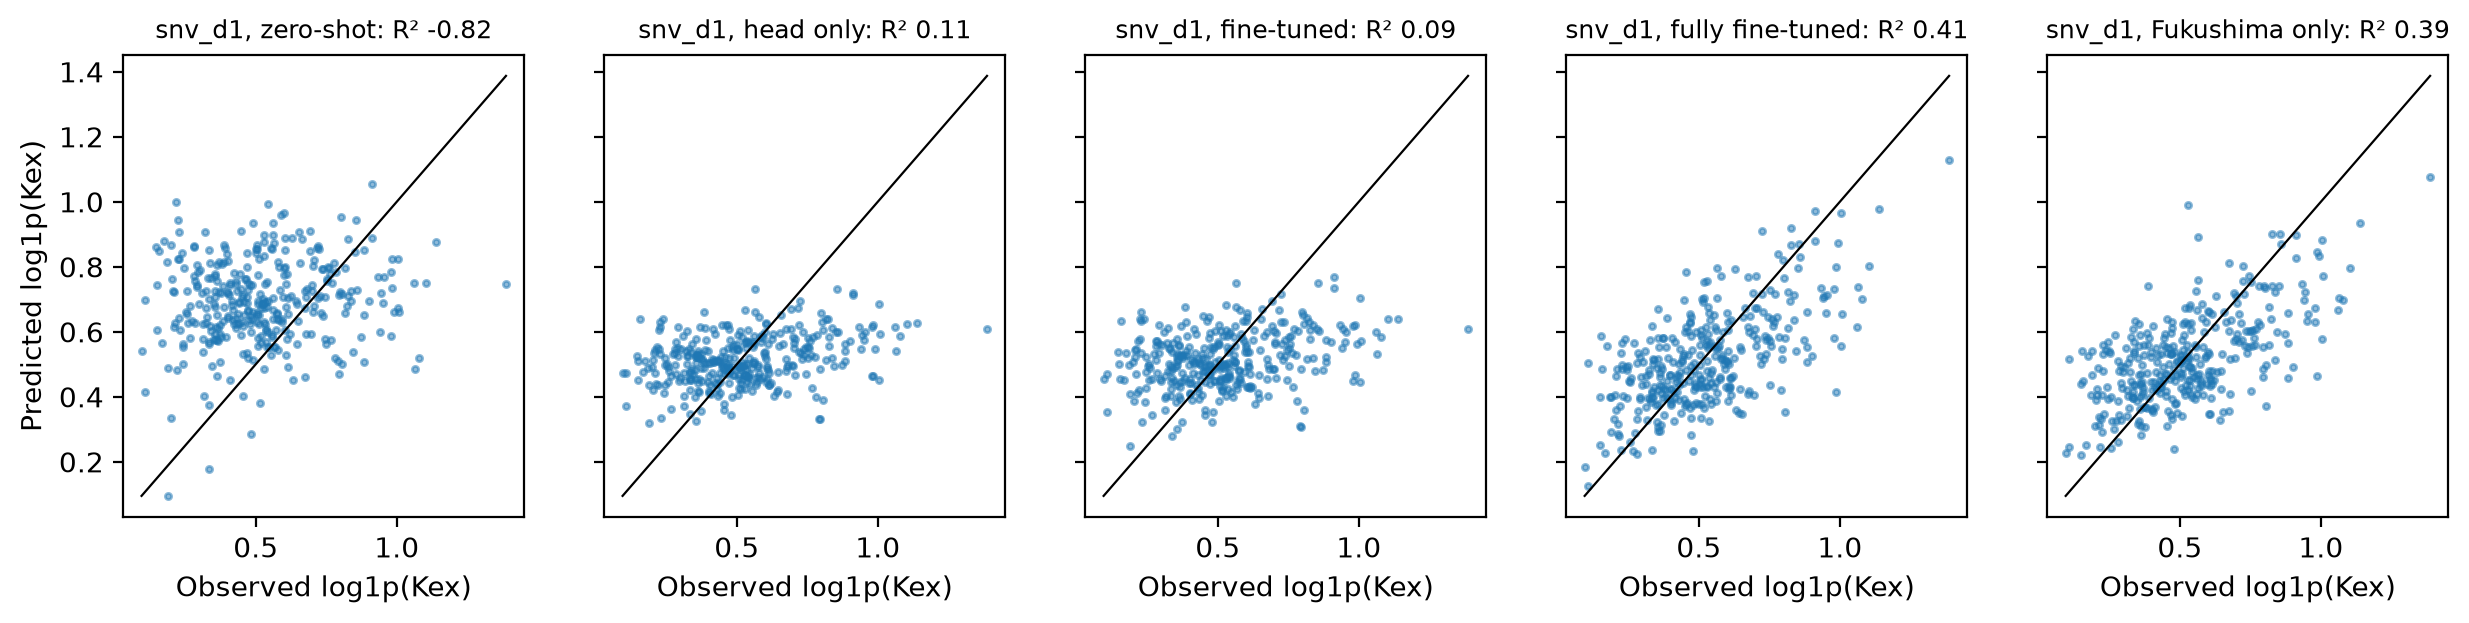

In [ ]:
#| fukudata
plot_preds(preds, yt, label='log1p(Kex)');

## Checks

The OSSL validation R² covers OSSL's whole Kex range. The pretrained model is scored again on its OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima Kex:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
np.expm1([lo, hi]).round(2), {k: round(v, 3) for k, v in range_check(Xo_d, yo, pretrained, lo, hi).items()}

(array([0.22, 1.63]),
 {'n all': 5767,
  'R² all': 0.794,
  'r all': np.float64(0.892),
  'n in range': 3227,
  'R² in range': 0.378,
  'r in range': np.float64(0.725)})

A spectral model predicts Kex partly through the soil properties that Kex varies with. Spearman correlations of Kex with CEC and with total carbon, in OSSL, in OSSL samples within Fukushima's Kex range, in OSSL Andisols, and in Fukushima:

In [ ]:
#| fukudata
ocols = {'k.ext_usda.a725_cmolc.kg': 'Kex', 'cec_usda.a723_cmolc.kg': 'CEC', 'c.tot_usda.a622_w.pct': 'C'}
op_ = om.source[list(ocols)].rename(columns=ocols).reindex(om.sample_ids)
fp = fuku.source.loc[fuku.sample_ids, ['target', 'soil_CEC', 'soil_C']].set_axis(['Kex', 'CEC', 'C'], axis=1)
in_rng = op_.Kex.between(*np.expm1([lo, hi]))
andisol = om.source['pedon.taxa_usda_txt'].reindex(om.sample_ids).astype('string').str.contains(r'[a-z]ands?\b|andepts?\b', na=False).to_numpy()
def corrs(df): return {'Kex–CEC': df.Kex.corr(df.CEC, method='spearman'), 'Kex–C': df.Kex.corr(df.C, method='spearman'), 'CEC–C': df.CEC.corr(df.C, method='spearman'), 'n': len(df.dropna())}
pd.DataFrame({'OSSL': corrs(op_), 'OSSL in Fukushima range': corrs(op_[in_rng]), 'OSSL Andisols': corrs(op_[andisol]), 'Fukushima': corrs(fp)}).T.round(2)

,Kex–CEC,Kex–C,CEC–C,n
OSSL,0.60,0.36,0.56,53360.0
OSSL in Fukushima range,0.33,0.18,0.39,30494.0
OSSL Andisols,0.47,0.36,0.67,1444.0
Fukushima,0.29,0.03,0.41,1385.0


## Error analysis

Mean absolute error of `log1p(Kex)` by soil type, year and measurement batch. Each model's predictions are averaged over the seeds first:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
error_table(preds, yt, props['Soil_type_describe'], 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
Andosols,0.174,0.173,0.138,0.151,44
Forest soil,0.171,0.170,0.145,0.137,27
Glay soil,0.189,0.197,0.126,0.123,6
Lowland soil,0.150,0.153,0.122,0.127,244
Peat soil,0.236,0.230,0.170,0.172,14
Red yellow soil,0.195,0.199,0.215,0.174,6


In [ ]:
#| fukudata
error_table(preds, yt, props['year'].astype(int), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
2013,0.198,0.198,0.138,0.147,34
2014,0.179,0.176,0.147,0.153,53
2015,0.125,0.130,0.117,0.114,48
2016,0.135,0.136,0.110,0.114,58
2017,0.151,0.149,0.125,0.135,37
2018,0.174,0.182,0.150,0.148,46
2019,0.157,0.163,0.120,0.121,49
2020,0.186,0.196,0.143,0.155,16


In [ ]:
#| fukudata
error_table(preds, yt, sample_batches(idf[is_test]), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
batch 1,0.170,0.171,0.142,0.148,110
batch 2,0.154,0.158,0.124,0.126,231


## Findings

The pretrained model comes from one pretraining run. The Fukushima-side training was repeated with five seeds. Training on MPS is not fully deterministic, and the variation between pretraining runs is not measured. All results use SNV followed by the first derivative.

Cross-validation on the training samples chose a maximum learning rate of 3e-3 for both the fully fine-tuned and the Fukushima-only model, the highest rate tried. It chose 20 epochs for the fully fine-tuned model and 40 for the Fukushima-only model. The best rate is at the edge of the grid, so a higher rate may do better. In cross-validation, the two models were close: a validation R² of 0.30 for the fully fine-tuned model and 0.27 for the Fukushima-only model, with standard deviations over the folds of 0.05 to 0.07.

With these schedules, the fully fine-tuned model is slightly better on the test set: an R² of `log1p(Kex)` of 0.41 and a correlation of 0.64, against 0.37 and 0.61 for the Fukushima-only model. The standard deviations over the seeds are 0.01 and 0.03. Before tuning, with 21 epochs at 1e-3 for both models, the gap was larger (0.37 against 0.30). Most of that gap came from undertraining the Fukushima-only model. The pretrained model needs half the epochs.

The best model has an RMSE of 0.31 cmolc/kg, against a standard deviation of 0.41 cmolc/kg for the test Kex values.

The OSSL backbone does not work unchanged. Zero-shot prediction fails (R² below 0, correlation 0.13). A linear head on the frozen backbone gives an R² of 0.11, and fastai's `fine_tune`, whose backbone trains at a maximum learning rate of 5e-6, gives 0.09. These models keep their default schedules.

The zero-shot failure is not explained by Fukushima's narrower Kex range: on OSSL validation samples within that range, the pretrained model keeps a correlation of 0.73. Nor is it explained by the relation between Kex and the soil: the Spearman correlation of Kex with CEC is 0.29 in Fukushima and 0.33 in OSSL samples within the same range.

The fully fine-tuned and Fukushima-only models have similar errors in each soil type, year and batch.